<a href="https://colab.research.google.com/github/fmezacr/DataScienceTEC/blob/master/ML_Titanic_EDA_Preprocesamiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

<div style="font-size:small;">

MIT License

Copyright (c) [2026] Felipe Meza-Obando

*Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software for educational purposes only. You must give author appropriate credit, provide a link to the license and source, and indicate if changes were made.*
</div>

---

# Machine Learning aplicado: del EDA a la clasificación, Caso Titanic

**Problema:** predecir si un pasajero sobrevivió (`Survived`: 1 = sí, 0 = no) a partir de información de los pasajeros. **Objetivo docente:** examinar datos, tomar decisiones de preprocesamiento y comparar dos clasificadores sencillos.

**Flujo:** 1. Carga y separación → 2. EDA → 3. Decisiones y preprocesamiento → 4. Benchmark → 5. Sobreajuste y evaluación → 6. Conclusiones → 7. Conceptos para seguir aprendiendo.

**Regla importante:** usaremos entrenamiento (80 %) para explorar, preparar y entrenar, y prueba (20 %) para evaluar ambos modelos al final. No utilizaremos validación cruzada ni `Pipeline` en el ejercicio.

## 1. Carga, calidad inicial y separación
**¿Qué hacemos?** Cargamos un dataset público y revisamos sus columnas. Después separamos los datos en 80 % entrenamiento y 20 % prueba.

**¿Por qué importa?** La variable objetivo no debe intervenir en el cálculo de imputaciones o escalados. La muestra de prueba debe permanecer sin consultar hasta el cierre.

**¿Qué nos indican los resultados?** Veremos tamaño, estructura y proporción de clases en los conjuntos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

SEED = 42
URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(URL)
print("Filas y columnas:", df.shape)
display(df.head())
print("Duplicados completos:", df.duplicated().sum())
print("Distribución general de la variable objetivo:")
display(df['Survived'].value_counts(normalize=True).rename('Proporción').round(3))

Filas y columnas: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Duplicados completos: 0
Distribución general de la variable objetivo:


,Proporción
Survived,
0,0.616
1,0.384


In [2]:
# Partición estratificada: 80 % entrenamiento y 20 % prueba.
train, test = train_test_split(df, test_size=0.20, stratify=df['Survived'], random_state=SEED)
print('Entrenamiento:', len(train), '| Prueba:', len(test))

Entrenamiento: 712 | Prueba: 179


## 2. EDA: explorar antes de transformar
**¿Qué hacemos?** Estudiamos *únicamente entrenamiento*: calidad, distribuciones y relación de variables con la supervivencia.

**¿Por qué importa?** El EDA sirve para justificar qué variables mantener, cuáles descartar y qué operaciones realizar.

**¿Qué nos indican los resultados?** Cada salida se interpreta con los números calculados: no suponemos un resultado antes de ejecutarla.

### 2.1 Calidad de datos y tipos
Una variable con muchos faltantes puede ser poco práctica. Un identificador, aunque esté completo, no es necesariamente un predictor útil.

In [3]:
calidad = pd.DataFrame({
    'tipo': train.dtypes.astype(str),
    'faltantes': train.isna().sum(),
    '% faltantes': (100*train.isna().mean()).round(1),
    'valores distintos': train.nunique(dropna=True)
}).sort_values('% faltantes', ascending=False)
display(calidad)
print('Resumen numérico (entrenamiento):')
display(train[['Age','Fare','SibSp','Parch']].describe().round(2))
print('Interpretación: columna más incompleta:', calidad.index[0],
      f"({calidad.iloc[0]['% faltantes']:.1f}% de faltantes)")

,tipo,faltantes,% faltantes,valores distintos
Cabin,object,552,77.5,127
Age,float64,137,19.2,85
Embarked,object,2,0.3,3
PassengerId,int64,0,0.0,712
Name,object,0,0.0,712
Pclass,int64,0,0.0,3
Survived,int64,0,0.0,2
Sex,object,0,0.0,2
Parch,int64,0,0.0,7
SibSp,int64,0,0.0,7


Resumen numérico (entrenamiento):


,Age,Fare,SibSp,Parch
count,575.00,712.00,712.00,712.00
mean,29.81,31.82,0.49,0.39
std,14.49,48.06,1.06,0.84
min,0.42,0.00,0.00,0.00
25%,21.00,7.90,0.00,0.00
50%,28.50,14.45,0.00,0.00
75%,39.00,31.00,1.00,0.00
max,80.00,512.33,8.00,6.00


Interpretación: columna más incompleta: Cabin (77.5% de faltantes)


### 2.2 Distribución del objetivo
**Pregunta:** ¿hay más personas sobrevivientes o no sobrevivientes? Si la distribución es desigual, *accuracy* por sí sola puede ser insuficiente.

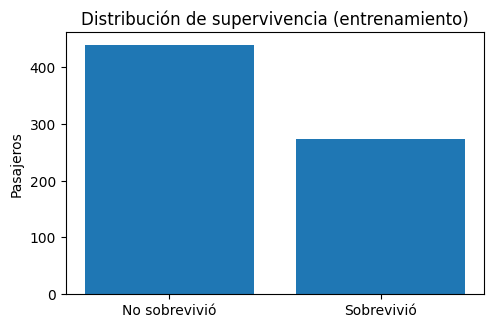

Sobrevivió el 38.3% de los pasajeros de entrenamiento.


In [4]:
conteos = train['Survived'].value_counts().reindex([0,1],fill_value=0)
fig, ax = plt.subplots(figsize=(5.4,3.4))
ax.bar(['No sobrevivió','Sobrevivió'],conteos.values)
ax.set(ylabel='Pasajeros', title='Distribución de supervivencia (entrenamiento)')
plt.show()
print(f"Sobrevivió el {100*conteos.loc[1]/conteos.sum():.1f}% de los pasajeros de entrenamiento.")

### 2.3 Variables categóricas
**Pregunta:** ¿cambia la tasa de supervivencia por sexo o clase? Comparamos **tasas**, no conteos totales; las cantidades de pasajeros pueden ser muy diferentes entre grupos.

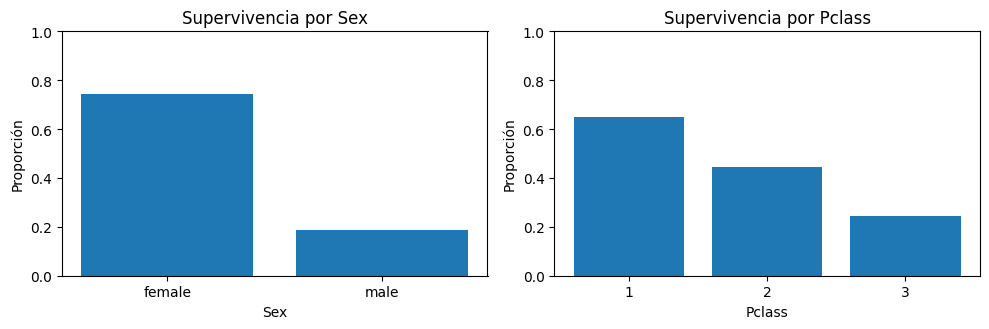

Tasa de supervivencia por Sex:


,pasajeros,tasa
Sex,,
female,253,0.743
male,459,0.185


Tasa de supervivencia por Pclass:


,pasajeros,tasa
Pclass,,
1,171,0.649
2,150,0.447
3,391,0.243


In [5]:
fig, axs = plt.subplots(1,2,figsize=(10,3.4))
for ax,col,orden in zip(axs,['Sex','Pclass'],[['female','male'],[1,2,3]]):
    tasas = train.groupby(col)['Survived'].mean().reindex(orden)
    ax.bar([str(i) for i in tasas.index], tasas.values)
    ax.set(title=f'Supervivencia por {col}', xlabel=col, ylabel='Proporción', ylim=(0,1))
plt.tight_layout(); plt.show()
for col in ['Sex','Pclass']:
    print(f'Tasa de supervivencia por {col}:')
    display(train.groupby(col)['Survived'].agg(pasajeros='size',tasa='mean').round(3))

### 2.4 Variables numéricas
**Pregunta:** ¿la edad y la tarifa presentan diferencias entre los dos grupos? Las distribuciones ayudan a identificar asimetría, dispersión y valores extremos. No eliminaremos valores altos solo por parecer inusuales.

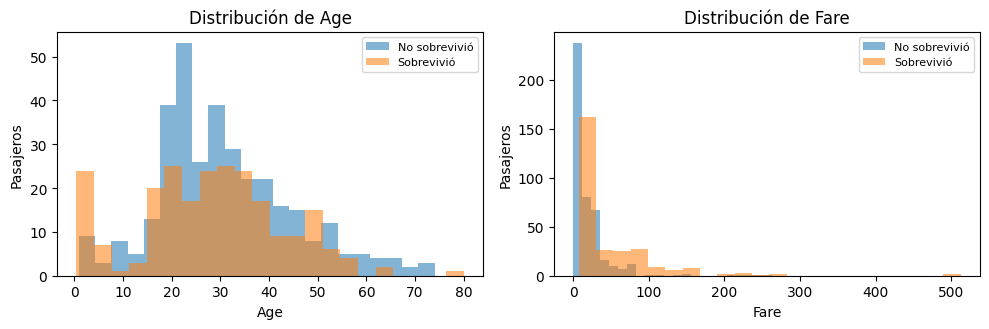

,Age,Fare
Survived,,
0,28.25,10.5
1,29.00,26.0


Las medianas anteriores permiten describir diferencias observadas, no relaciones causales.


In [6]:
fig,axs = plt.subplots(1,2,figsize=(10,3.4))
for ax,col in zip(axs,['Age','Fare']):
    for clase,etiqueta in [(0,'No sobrevivió'),(1,'Sobrevivió')]:
        ax.hist(train.loc[train['Survived']==clase,col].dropna(), bins=22, alpha=.55, label=etiqueta)
    ax.set(xlabel=col,ylabel='Pasajeros',title=f'Distribución de {col}')
    ax.legend(fontsize=8)
plt.tight_layout();plt.show()
display(train.groupby('Survived')[['Age','Fare']].median().round(2))
print('Las medianas anteriores permiten describir diferencias observadas, no relaciones causales.')

### 2.5 Grupos pequeños: composición familiar
**Pregunta:** ¿se relaciona el tamaño del grupo familiar con la supervivencia? Evitamos extraer conclusiones firmes de grupos con muy pocos registros.

In [7]:
familia = train.assign(FamilySize=train['SibSp']+train['Parch']+1)
tabla_familia = familia.groupby('FamilySize')['Survived'].agg(n='size',tasa='mean').round(3)
display(tabla_familia)
print('Una tasa calculada sobre pocos pasajeros es menos estable que otra basada en muchos.')

,n,tasa
FamilySize,,
1,434,0.300
2,129,0.550
3,77,0.623
4,22,0.727
5,14,0.214
6,16,0.062
7,11,0.364
8,4,0.000
11,5,0.000


Una tasa calculada sobre pocos pasajeros es menos estable que otra basada en muchos.


## 3. Preprocesamiento: decisiones justificadas por el EDA
**¿Qué hacemos?** Seleccionamos columnas, creamos una variable comprensible, completamos faltantes y convertimos categorías en números.

**¿Por qué importa?** Los algoritmos requieren datos numéricos completos. Cada decisión debe tener una razón práctica y debe usar **solo entrenamiento** para aprender estadísticas.

**¿Qué nos indican los resultados?** Comprobaremos las columnas finales, los faltantes y la escala de las variables.

| Variable o grupo | Decisión | Justificación |
|---|---|---|
| `PassengerId`, `Name`, `Ticket` | Excluir | Identificadores o texto difícil de utilizar coherentemente en un ejemplo básico. |
| `Cabin` | Excluir | Verificar arriba su elevado porcentaje de faltantes; su extracción requeriría ingeniería adicional. |
| `Age` | Conservar e imputar **mediana de entrenamiento** | Edad interpretable; la mediana resiste valores extremos. |
| `Fare` | Conservar | Variable numérica útil para estudiar el problema. |
| `Sex`, `Embarked` | Conservar, imputar categoría más frecuente si falta y codificar | Son categorías, no magnitudes numéricas. |
| `Pclass` | Conservar como **categoría** | Aunque se almacene con números, expresa grupos de clase. |
| `SibSp`, `Parch` | Reemplazar por `FamilySize = SibSp + Parch + 1` | Resumen simple del tamaño familiar; reduce el número de entradas. |
| Variables numéricas | Estandarizar **solo para regresión logística** | Coloca magnitudes en escalas comparables; el árbol no lo necesita. |

**Importante:** son elecciones pedagógicas razonables, no una afirmación de que sean óptimas. La proporción de faltantes y las diferencias entre grupos se observan en las salidas anteriores.

In [8]:
# 3.1 Elegimos y construimos las mismas características en ambas particiones.
def seleccionar_columnas(datos):
    X = datos[['Age','Fare','Sex','Embarked','Pclass','SibSp','Parch']].copy()
    X['FamilySize'] = X['SibSp'] + X['Parch'] + 1
    return X.drop(columns=['SibSp','Parch'])

X_train = seleccionar_columnas(train)
X_test = seleccionar_columnas(test)
y_train, y_test = train['Survived'], test['Survived']
numericas = ['Age','Fare','FamilySize']
categoricas = ['Sex','Embarked','Pclass']
print('Columnas seleccionadas:', X_train.columns.tolist())
display(X_train.head())

Columnas seleccionadas: ['Age', 'Fare', 'Sex', 'Embarked', 'Pclass', 'FamilySize']


,Age,Fare,Sex,Embarked,Pclass,FamilySize
692,NaN,56.4958,male,S,3,1
481,NaN,0.0000,male,S,2,1
527,NaN,221.7792,male,S,1,1
855,18.0,9.3500,female,S,3,2
801,31.0,26.2500,female,S,2,3


In [9]:
# 3.2 Imputación: valores calculados SOLO con entrenamiento.
medianas = X_train[numericas].median()
modas = X_train[categoricas].mode(dropna=True).iloc[0]
print('Medianas usadas para imputar:')
display(medianas.to_frame('valor'))
print('Categorías más frecuentes usadas para imputar:')
display(modas.to_frame('valor'))

for X in (X_train, X_test):
    X[numericas] = X[numericas].fillna(medianas)
    X[categoricas] = X[categoricas].fillna(modas)
print('Faltantes restantes en entrenamiento:', X_train.isna().sum().sum())

Medianas usadas para imputar:


,valor
Age,28.5000
Fare,14.4542
FamilySize,1.0000


Categorías más frecuentes usadas para imputar:


,valor
Sex,male
Embarked,S
Pclass,3


Faltantes restantes en entrenamiento: 0


In [10]:
# 3.3 Codificación one-hot: una columna de 0/1 por categoría.
# Las columnas permitidas se definen a partir de entrenamiento.
X_train = pd.get_dummies(X_train, columns=categoricas, dtype=int)
columnas_entrenamiento = X_train.columns
X_test = pd.get_dummies(X_test, columns=categoricas, dtype=int).reindex(columns=columnas_entrenamiento, fill_value=0)
print('Antes: 6 variables seleccionadas. Después:', X_train.shape[1], 'columnas numéricas.')
display(X_train.head())
print('¿Hay valores faltantes?', X_train.isna().any().any())

Antes: 6 variables seleccionadas. Después: 11 columnas numéricas.


,Age,Fare,FamilySize,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Pclass_1,Pclass_2,Pclass_3
692,28.5,56.4958,1,0,1,0,0,1,0,0,1
481,28.5,0.0000,1,0,1,0,0,1,0,1,0
527,28.5,221.7792,1,0,1,0,0,1,1,0,0
855,18.0,9.3500,2,1,0,0,0,1,0,0,1
801,31.0,26.2500,3,1,0,0,0,1,0,1,0


¿Hay valores faltantes? False


### 3.4 ¿Cuándo estandarizamos?
La **regresión logística** utiliza coeficientes y regularización: estandarizar las variables numéricas puede facilitar su ajuste y una penalización más equilibrada. El **árbol de decisión** separa los datos mediante umbrales y no necesita escalado.

La estandarización transforma cada valor mediante `z = (x - media) / desviación estándar`. **Media y desviación estándar se calculan solo en entrenamiento.**

In [11]:
# Solo la regresión logística utiliza datos escalados.
escalador = StandardScaler()
X_train_lr, X_test_lr = X_train.copy(), X_test.copy()
X_train_lr[numericas] = escalador.fit_transform(X_train[numericas])
X_test_lr[numericas] = escalador.transform(X_test[numericas])
print('Antes de escalar (medias de entrenamiento):')
display(X_train[numericas].mean().round(2))
print('Después de escalar (medias aproximadamente 0):')
display(X_train_lr[numericas].mean().round(2))

Antes de escalar (medias de entrenamiento):


,0
Age,29.56
Fare,31.82
FamilySize,1.88


Después de escalar (medias aproximadamente 0):


,0
Age,0.0
Fare,-0.0
FamilySize,0.0


## 4. Benchmark: dos clasificadores
**¿Qué hacemos?** Comparamos **regresión logística** (modelo lineal regularizado) y **árbol de decisión** (reglas sucesivas de separación).

**¿Por qué importa?** El primero sirve de referencia; el segundo puede capturar relaciones no lineales. Ambos utilizan el mismo 80 % para entrenar y el mismo 20 % para evaluar.

**¿Qué nos indican los resultados?** Calculamos accuracy, precision, recall y F1. *Precision* mide la proporción de predicciones positivas correctas; *recall*, la proporción de supervivientes identificados; F1 resume ambas.

In [12]:
modelos = {
    'Regresión logística': LogisticRegression(max_iter=1000, random_state=SEED),
    'Árbol de decisión': DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=SEED)
}

def metricas(reales, pred):
    return {'Accuracy': accuracy_score(reales,pred),
            'Precision': precision_score(reales,pred,zero_division=0),
            'Recall': recall_score(reales,pred,zero_division=0),
            'F1': f1_score(reales,pred,zero_division=0)}

resultados = []
predicciones_test = {}
for nombre, modelo in modelos.items():
    A, B = (X_train_lr, X_test_lr) if nombre == 'Regresión logística' else (X_train, X_test)
    modelo.fit(A, y_train)
    predicciones_test[nombre] = modelo.predict(B)
    for conjunto, X, y in [('Entrenamiento', A, y_train), ('Prueba', B, y_test)]:
        resultados.append({'Modelo': nombre, 'Conjunto': conjunto, **metricas(y, modelo.predict(X))})
tabla = pd.DataFrame(resultados).set_index(['Modelo','Conjunto'])
display(tabla.round(3))

Accuracy  Precision  Recall     F1
Modelo              Conjunto                                         
Regresión logística Entrenamiento     0.808      0.772   0.707  0.738
                    Prueba            0.799      0.780   0.667  0.719
Árbol de decisión   Entrenamiento     0.833      0.893   0.641  0.746
                    Prueba            0.777      0.809   0.551  0.655

## 5. Sobreajuste y evaluación
**¿Qué hacemos?** Comparamos los resultados de entrenamiento (80 %) y prueba (20 %) y examinamos las matrices de confusión de ambos modelos.

**¿Por qué importa?** Una diferencia grande entre entrenamiento y prueba puede señalar sobreajuste. En este ejemplo básico no usamos un conjunto de validación separado.

**¿Qué nos indican los resultados?** La prueba sirve para ilustrar cómo se desempeñan los modelos en datos no vistos. **No ajustamos hiperparámetros ni volvemos a entrenar tomando decisiones a partir de los resultados de prueba**, porque eso sesgaría la evaluación.

In [13]:
resumen = tabla['F1'].unstack('Conjunto')
resumen['Diferencia (entrenamiento - prueba)'] = resumen['Entrenamiento'] - resumen['Prueba']
display(resumen.round(3))
print('Una diferencia positiva grande puede indicar sobreajuste, pero no lo demuestra por sí sola.')

Conjunto,Entrenamiento,Prueba,Diferencia (entrenamiento - prueba)
Modelo,,,
Regresión logística,0.738,0.719,0.019
Árbol de decisión,0.746,0.655,0.091


Una diferencia positiva grande puede indicar sobreajuste, pero no lo demuestra por sí sola.


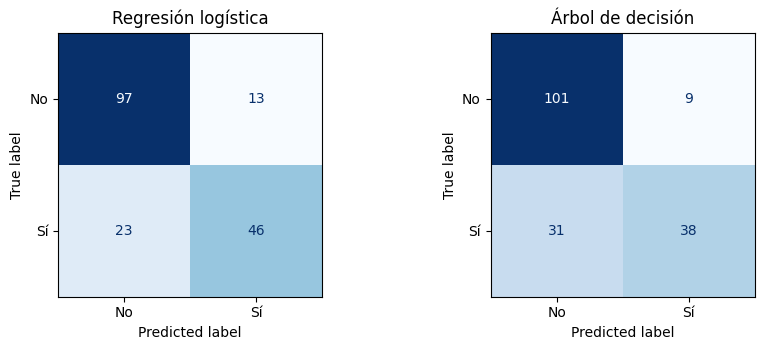

In [14]:
# Matrices de confusión para ambos modelos sobre el mismo conjunto de prueba.
fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (nombre, pred) in zip(axs, predicciones_test.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['No','Sí'],
                                            cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

## 6. Conclusiones basadas en resultados
**¿Qué hacemos?** Resumimos las métricas obtenidas y su diferencia entre entrenamiento y prueba.

**¿Por qué importa?** La comparación es educativa: con una única división 80/20 no podemos afirmar que un modelo sea universalmente superior.

**¿Qué nos indican los resultados?** El siguiente código identifica el mayor F1 **observado en prueba**, sin usarlo para reajustar o seleccionar un modelo para producción.

In [15]:
prueba = tabla.xs('Prueba', level='Conjunto')
mejor_observado = prueba['F1'].idxmax()
print('Mayor F1 observado en esta partición de prueba:', mejor_observado)
print('Resultados de prueba:')
display(prueba.round(3))
print('Diferencias de F1 entre entrenamiento y prueba:')
display(resumen[['Diferencia (entrenamiento - prueba)']].round(3))
print('Precision y recall son relevantes porque distinguen los dos tipos de errores de clasificación.')
print('Limitaciones: datos históricos, relaciones no causales y una única partición 80/20.')

Mayor F1 observado en esta partición de prueba: Regresión logística
Resultados de prueba:


,Accuracy,Precision,Recall,F1
Modelo,,,,
Regresión logística,0.799,0.780,0.667,0.719
Árbol de decisión,0.777,0.809,0.551,0.655


Diferencias de F1 entre entrenamiento y prueba:


Conjunto,Diferencia (entrenamiento - prueba)
Modelo,
Regresión logística,0.019
Árbol de decisión,0.091


Precision y recall son relevantes porque distinguen los dos tipos de errores de clasificación.
Limitaciones: datos históricos, relaciones no causales y una única partición 80/20.


## 7. Para seguir aprendiendo: ¿qué son la validación cruzada y un `Pipeline`?

### Validación cruzada (*cross-validation*, CV)
Es un procedimiento para **estimar qué tan bien generaliza un modelo usando varias particiones de los datos de desarrollo**. Por ejemplo, en CV de cinco particiones se divide el conjunto de desarrollo en cinco bloques: se entrena cinco veces, dejando un bloque diferente para validar en cada ocasión, y luego se resumen los cinco resultados.

**¿Para qué sirve?** Reduce la dependencia de una única separación entrenamiento/validación y permite estimar la variabilidad del desempeño. En clasificación, es habitual usar **CV estratificada** para mantener proporciones de clases parecidas en cada bloque. **No sustituye la prueba final independiente.**

### `Pipeline` de scikit-learn
Es una **secuencia organizada de operaciones** que aplica primero transformaciones (por ejemplo imputar, codificar, escalar) y después entrena un modelo. Al predecir, aplica las mismas transformaciones aprendidas.

**¿Para qué sirve?** Evita repetir código, hace más reproducible el flujo y ayuda a prevenir fugas de información, especialmente cuando se combina con validación cruzada: cada transformación se ajusta usando solo los datos de entrenamiento de cada partición.

**¿Por qué no los usamos aquí?** Para que se observen las decisiones y transformaciones **paso a paso**, antes de automatizarlas. En proyectos reales suelen ser muy convenientes.

